# Empirical-Bayes Multi-modal Contrastive Analysis (EB-MoCAVI)

Empirical-Bayes Multi-modal Contrastive Analysis (EB-MoCAVI) is a generative model designed to analyze single-cell multi-omics data and for prediction of perturbation effects via an empirical-Bayes framework. In this tutorial, we will demonstrate how to use EB-MoCAVI to predict perturbation effects on gene expression based on optical pooled screening data. We refer to the reader to the original MoCAVI tutorial for details on data preprocessing and model training. Here, we will focus on the empirical-Bayes aspects of EB-MoCAVI.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import torch
from tqdm import tqdm

from mocavi import EBMoCAVIModel

# make sure cuda is available
print("CUDA available:", torch.cuda.is_available())

scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
Seed set to 0


CUDA available: False
Last run with scvi-tools version: 1.3.0


To get started, download the data used in the tutorial

```bash
mkdir data && cd data
curl -L -A "Mozilla/5.0" -o main_ops_bulk.h5ad "https://figshare.com/ndownloader/files/59971082?private_link=9670a98d3a8ad87fb802"
curl -L -A "Mozilla/5.0" -o main_pseq_singlecell.h5ad "https://figshare.com/ndownloader/files/59971088?private_link=9670a98d3a8ad87fb802"
cd ..
```

If the curl command does not work, please download the file manually from the link using a web browser.

In [2]:
# let's load the pseq data
adata = sc.read_h5ad("../data/main_pseq_singlecell.h5ad")
adata

AnnData object with n_obs × n_vars = 136906 × 10000
    obs: 'batch', 'Total_UMI', 'MT_UMI', 'Percent_MT_UMI', 'log10_Total_UMI', 'Total_ADT', 'Total_HTO', 'Total_GRNA', 'hto_label', 'grna_label', 'perturb_label', 'Log_Total_UMI', 'Log_Total_ADT', 'score_s', 'score_g2m', 'leiden', 'score_hotspot1', 'score_hotspot2', 'score_hotspot3', 'score_hotspot4', 'score_hotspot5', 'score_hotspot6', 'score_hotspot7', '_scvi_labels', '_scvi_batch', 'perturb_DE', 'perturb_leiden', 'perturb_leiden_mocavi', 'perturb_leiden_salient'
    var: 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'batch_colors', 'guide_distance', 'hto_label_colors', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'perturb_leiden_colors', 'perturb_leiden_mocavi_colors', 'perturb_leiden_salient_colors', 'protein_names', 'umap'
    obsm: 'X_background_umap', 'X_pca', 'X_salient_umap', 'X_totalVI', 'X_totalVI_umap', 

In [3]:
# the obs field "perturb_DE" contains the perturbation information
adata.obs["perturb_DE"].value_counts()

perturb_DE
Control    25952
Cdkn1a      1164
Ikzf1       1022
Med25        826
Mettl14      781
           ...  
Tinf2         48
Rpl4          48
Lrr1          46
Birc5         46
Kif23         44
Name: count, Length: 531, dtype: int64

In [4]:
# let's load the ops bulk data
bulk_ops = sc.read_h5ad("../data/main_ops_bulk.h5ad")
bulk_ops

AnnData object with n_obs × n_vars = 1689 × 70
    obs: 'norms', 'olfr', 'guide_distance', 'nuclei_solidity', 'cell_orientation', 'cell_solidity', 'nuclei_extent', 'nuclei_compactness', 'nuclei_axisminorlength', 'nuclei_areaconvex', 'cell_areaconvex', 'cell_perimeter', 'nuclei_eccentricity', 'nuclei_orientation', 'nuclei_formfactor', 'nuclei_axismajorlength', 'cell_formfactor', 'cell_compactness', 'nuclei_perimeter', 'cell_axisminorlength', 'cell_axismajorlength', 'cell_eccentricity', 'cell_extent', 'nuclei_area', 'cell_area', 'leiden', 'leiden_euclidean'

In [5]:
# check for intersection of perturbation list
pseq_genes = adata.obs["perturb_DE"].unique().tolist()
ops_genes = bulk_ops.obs_names
print("Number of genes in pseq:", len(pseq_genes))
print("Number of genes in ops:", len(ops_genes))
print("Number of genes in common:", len(set(pseq_genes) & set(ops_genes)))
common_genes = list(set(pseq_genes) & set(ops_genes))
# reduce to common genes
adata = adata[adata.obs["perturb_DE"].isin(common_genes + ["Control"]), :].copy()
bulk_ops = bulk_ops[common_genes, :].copy()

Number of genes in pseq: 531
Number of genes in ops: 1689
Number of genes in common: 514


In [6]:
# now we would like to add the OP embedding of each perturbations to the dataframe
n_features = bulk_ops.shape[1]
emb_obsm = pd.DataFrame(np.zeros((adata.shape[0], n_features)), index=adata.obs_names, columns=bulk_ops.var_names)
for cell_id in tqdm(adata.obs_names):
    # get the perturbation of the cell
    perturbation = adata.obs.loc[cell_id, "perturb_DE"]
    # add the embedding to the dataframe
    if perturbation == "Control":
        emb_obsm.loc[cell_id] = np.zeros((1, n_features))
    else:
        emb_obsm.loc[cell_id] = bulk_ops[perturbation].X
# add the embedding to the adata object
adata.obsm["embedding_ops"] = emb_obsm.values

100%|██████████| 135668/135668 [00:34<00:00, 3971.56it/s]


INFO     Using column names from adata.uns['protein_names']                                                        
INFO     Generating sequential column names                                                                        


/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator=='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/trainer/setup.py:166: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performanc

Epoch 1/2:   0%|          | 0/2 [00:00<?, ?it/s]

/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 35. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Epoch 2/2:  50%|█████     | 1/2 [01:21<01:21, 81.60s/it, v_num=1, train_loss_step=5.06e+3, train_loss_epoch=5.27e+3]

/Users/lopezr55/miniconda3/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 128. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Epoch 2/2: 100%|██████████| 2/2 [02:41<00:00, 80.33s/it, v_num=1, train_loss_step=5.13e+3, train_loss_epoch=5.12e+3]

`Trainer.fit` stopped: `max_epochs=2` reached.


Epoch 2/2: 100%|██████████| 2/2 [02:41<00:00, 80.52s/it, v_num=1, train_loss_step=5.13e+3, train_loss_epoch=5.12e+3]


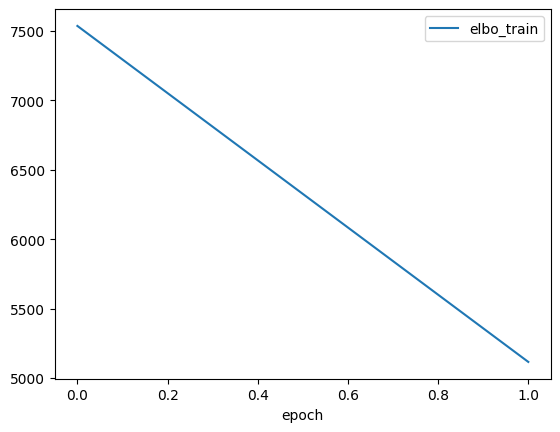

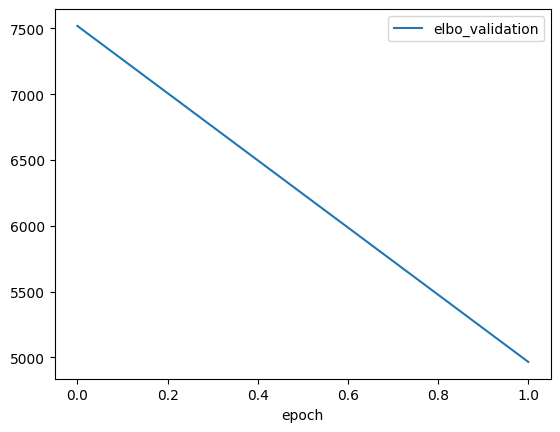

In [ ]:
# we start the first step of the EBMoCAVI model training
# this consists in standard MoCAVI training to learn disentangled latent representations
train = True
max_epochs = 100
vehicle_indices = np.where(adata.obs["perturb_DE"] == "Control")[0]
target_indices = np.where(adata.obs["perturb_DE"] != "Control")[0]
adata.uns["protein_names"] = list(adata.obsm["raw_proteins"].columns)
if train:
    EBMoCAVIModel.setup_anndata(
        adata,
        batch_key="batch",
        labels_key="perturb_DE",
        layer="counts",
        protein_expression_obsm_key="raw_proteins",
        protein_names_uns_key="protein_names",
        empirical_prior_key="embedding_ops",
    )

    # train the VAE
    model = EBMoCAVIModel(
        adata,
        n_genes=adata.n_vars,
        n_regions=0,
        n_salient_latent=50,
        n_background_latent=8,
        n_layers_decoder=2,
        reweighting_mode="auto",
        wasserstein_reg=0.01,
        n_layers_encoder=2,
    )
    model.train(
        max_epochs=max_epochs,
        background_indices=vehicle_indices,
        target_indices=target_indices,
        check_val_every_n_epoch=1,
        early_stopping=True,
        plan_kwargs={
            "n_epochs_kl_warmup": int(max_epochs * 0.8),
            "lr": 0.001,
        },
    )
    model.history["elbo_train"].plot()
    model.history["elbo_validation"].plot()
    model.save("data/ebmocavi_embedding_ops_model", overwrite=True)
else:
    model = EBMoCAVIModel.load("data/ebmocavi_embedding_ops_model", adata)
    model.history["elbo_train"].plot()
    model.history["elbo_validation"].plot()

In [9]:
# our second training step consists in fitting the empirical prior with maximum likelihood
# this allows us to map the OPS embeddings to the latent space learned by MoCAVI
# later, we will be able to generate perturbation effects by sampling from the empirical prior for unseen perturbations

# note: this function the presence of a reference label in the data, here "Control".
# The labels used are the same as those used in the initial MoCAVI training (here "perturb_DE")
finetune = True
finetune_max_epochs = 2
# finetune_max_epochs = 5
finetune_n_samples_per_cell = 10
if finetune:
    model.maximum_likelihood_training(
        learning_rate=1e-3,
        n_samples_per_cell=finetune_n_samples_per_cell,
        max_epochs=finetune_max_epochs,
        control_label="Control",
    )
    model.save("data/ebmocavi_predictor_fine_tuned_embedding_ops_model", overwrite=True)
else:
    model = EBMoCAVIModel.load("data/ebmocavi_predictor_fine_tuned_embedding_ops_model", adata)

100%|██████████| 858/858 [00:17<00:00, 49.79it/s]


Epoch 1/2, Avg NLL: 75.557592


100%|██████████| 858/858 [00:16<00:00, 52.47it/s]


Epoch 2/2, Avg NLL: 75.509683


In [ ]:
# now we would like to create a dataframe with the embedding of each perturbations we would like to predict or denoise
dict_emb_ops = {}
for perturbation in tqdm(bulk_ops.obs_names):
    # get the perturbation of the cell
    dict_emb_ops[perturbation] = np.array(bulk_ops[perturbation].X)[0]

100%|██████████| 514/514 [00:00<00:00, 3147.04it/s]


In [ ]:
# A first downstream task for EBMoCAVI is to predict the effect of unseen perturbations
# To do so, we can use the learned empirical prior to sample from the latent space.
# As EBMoCAVI is a generative model, we can then obtain different kinds of predictions:
# 1. the predicted fold change in expression compared to control
# 2. the predicted normalized expression values
# 3. the salient latent embedding
# 4. the background latent embedding
# We show here how to obtain these different predictions
prediction_dict = model.get_label_prior_total_fold_change(labels=dict_emb_ops, n_samples=100, control_label="Control")
de_exp = prediction_dict["fold_change_exp"]
normalized_values = prediction_dict["normalized_exp"]
salient_embedding = prediction_dict["salient"]
background_embedding = prediction_dict["background"]

260it [00:04, 63.25it/s]
514it [00:02, 212.38it/s]


In [ ]:
# A second downstream task for EBMoCAVI is to denoise training data in the case of perturbations with low cell numbers
# We specifically advise to use this function only when:
# 1. the number of cells per perturbation is low (<50) [if > 100 cells, this function will not have an effect]
# 2. the perturbation is not detected as having a significant effect compared to control
# The processed data below has only significant perturbations, so we just show how to use the function

# Step 1: import the anndata with the perturbation that have low cell numbers
adata_denoise = adata.copy()
# Step 2: make a dictionary with the embeddings of the perturbations to denoise
dict_denoise_emb_ops = {}
for perturbation in adata_denoise.obs["perturb_DE"].unique().tolist():
    if perturbation == "Control":
        dict_denoise_emb_ops[perturbation] = np.zeros((bulk_ops.shape[1],))
    else:
        dict_denoise_emb_ops[perturbation] = np.array(bulk_ops[perturbation].X)[0]
# Step 3: get the denoised outputs
denoise_dict = model.get_label_shrinkage_total_fold_change(
    dict_denoise_emb_ops, adata=adata_denoise, batch_size=1000, n_samples=100, control_label="Control"
)

# same as before, we can obtain different kinds of denoised outputs:
# 1. the denoised fold change in expression compared to control
# 2. the denoised normalized expression values
# 3. the denoised salient latent embedding
# 4. the denoised background latent embedding
denoised_de_exp = denoise_dict["fold_change_exp"]
denoised_normalized_values = denoise_dict["normalized_exp"]
denoised_salient_embedding = denoise_dict["salient"]
denoised_background_embedding = denoise_dict["background"]

Computing background: 260it [00:03, 71.92it/s]
Processing labels: 36it [00:02, 25.55it/s]

Label Sars: N=96, alpha=0.96, n_prior=0, n_post=1


Processing labels: 74it [00:03, 28.98it/s]

Label Tubgcp3: N=97, alpha=0.97, n_prior=0, n_post=1
Label Dido1: N=93, alpha=0.92, n_prior=0, n_post=1


Processing labels: 89it [00:04, 27.10it/s]

Label Mphosph10: N=66, alpha=0.62, n_prior=1, n_post=0


... (59 outputs left out)

Label Ndc80: N=58, alpha=0.53, n_prior=1, n_post=0
Label Cdc42: N=79, alpha=0.77, n_prior=1, n_post=0
Label Rpl35: N=86, alpha=0.84, n_prior=0, n_post=1
Label Tpr: N=68, alpha=0.64, n_prior=0, n_post=1


Processing labels: 515it [00:19, 26.46it/s]


Label Serbp1: N=97, alpha=0.97, n_prior=0, n_post=1
Label Cul1: N=66, alpha=0.62, n_prior=0, n_post=1
Label Preb: N=79, alpha=0.77, n_prior=0, n_post=1
Label Orc6: N=49, alpha=0.43, n_prior=0, n_post=1
Label Orc5: N=96, alpha=0.96, n_prior=0, n_post=1


{'fold_change_exp':             Rgs20   Atp6v1h  4732440D04Rik      St18    Pcmtd1   Gm26901  \
 Cbll1   -0.995015  0.211538      -0.832951  1.917277 -0.210978 -0.982811   
 Jak1    -0.913678  1.156712      -0.766261  2.087594  0.076933 -0.856405   
 Sephs1  -0.983924  0.430907      -0.823588  1.405029 -0.098913 -0.978415   
 Setd2   -0.988047  0.219262      -0.777834  1.530269  0.062731 -0.986931   
 Trappc1 -0.990821  0.147556      -0.862981  0.858176 -0.079020 -0.984610   
 ...           ...       ...            ...       ...       ...       ...   
 Nrbf2   -0.992780  0.442505      -0.818981  1.685154  0.145722 -0.980895   
 Cul1    -0.990151  0.369260      -0.798490  2.458226 -0.130128 -0.957457   
 Preb    -0.995540  0.087272      -0.859256  0.982128 -0.384474 -0.991198   
 Orc6    -0.993206  0.288013      -0.841184  1.709551 -0.194261 -0.987248   
 Orc5    -0.991295  0.305723      -0.869696  1.487078 -0.293324 -0.976809   
 
             Sntg1      Rrs1    Adhfe1  2610203C22Rik  